# 04 - Inhibitor dose and action: i, h_i, d_b

**Question.** How do the inhibitor dose (i), the steepness of its dose response (h_i) and the
rate at which it inactivates free enzyme (d_b) change the outcome of one antibiotic dose?

**Sweep.** 21 × 21 × 21 = 9,261 runs. i is log-spaced over the paper's dose range 0.1-10; h_i and d_b
span their SI randomized ranges. Antibiotic dose a0 = 2.15; all other parameters at their SI base
values. Note that the base inhibitor dose is i = 10 (the Fig. 2C dose), the top of the range; an
earlier version of this workstream used i = 1 as its baseline.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace
from src.model.ma2024_model import DEFAULT_PARAMS, BASE_A0, BASE_I
from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import axis, BASE_VALUES, RANGES, LOG_AXES
from src.analysis.plotting import (heatmap_slices, pair_heatmaps, marginal_effects, outcome_map,
                                   outcome_counts, timecourses, select, label, SHORT, OKABE_ITO, OUTCOME_COLORS)

PARAMS = ['i', 'h_i', 'd_b']
df = pd.read_csv(TABLES / "grid_i_hi_db.csv")
with np.errstate(divide="ignore"):
    df["log10_f_R"] = np.log10(df.f_R_final)
    df["log10_ns_min"] = np.log10(df.ns_min.clip(lower=1e-30))
    df["log10_nr_min"] = np.log10(df.nr_min.clip(lower=1e-30))
settled = df[~df.outcome.isin(["community collapsed", "not converged"])]
print(f"{len(df):,} runs; {len(settled):,} settled; fixed dose: " +
      ", ".join(f"{k} = {BASE_VALUES[k]:g}" for k in ("a0", "i") if k not in PARAMS))
pd.DataFrame([{"parameter": k, "base": BASE_VALUES[k], "min": df[k].min(), "max": df[k].max(),
               "values": df[k].nunique(), "spacing": "log" if k in LOG_AXES else "linear"} for k in PARAMS])

9,261 runs; 9,261 settled; fixed dose: a0 = 2.15


,parameter,base,min,max,values,spacing
0,i,10.0,0.1,10.0,21,log
1,h_i,2.0,1.0,5.0,21,linear
2,d_b,1.0,1.0,10.0,21,linear


## Overview of the endpoints

Minimum, median and maximum over the settled runs, and the value at the base point.

In [2]:
cols = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "peak_loss_total",
        "t_regain_S", "t_90_final_S", "t_steady_state"]
overview = settled[cols].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
base = select(df, {k: BASE_VALUES[k] for k in PARAMS})
overview["base point"] = base[cols].iloc[0].values
overview.index = [label(c) for c in cols]
print(f"S viable at the end: {df.sensitive_survives.mean():.1%} of runs | R gained share (f_R rose): "
      f"{(df.delta_log_ratio > 0).mean():.1%} | needed a horizon beyond 150: {(df.t_end > 150).mean():.1%}")
overview.round(3)

S viable at the end: 100.0% of runs | R gained share (f_R rose): 43.7% | needed a horizon beyond 150: 0.0%


,min,median,max,base point
Final resistant fraction f_R,0.407,0.491,0.509,0.433
Final Shannon diversity H,0.676,0.693,0.693,0.684
Final total density,3.636,4.010,4.188,3.832
Peak S loss,0.190,0.291,0.548,0.394
Peak total loss,0.152,0.269,0.569,0.410
S recovery time (back to start),3.500,6.000,14.500,8.500
Time for S to reach 90% of final,7.000,10.000,20.000,13.500
Time to steady state,8.500,12.000,22.000,15.500


## Outcome classes

**Plain model:** the paper's equations as they are. **With floor:** a population that falls below
one cell (10⁻⁹ of the carrying capacity) is removed for good. The two only differ when a run passes
through a very deep crash.

In [3]:
both = pd.concat([outcome_counts(df, "outcome").add_prefix("plain model: "),
                  outcome_counts(df, "outcome_floor").add_prefix("with floor: ")], axis=1).fillna(0)
both

,plain model: runs,plain model: % of grid,with floor: runs,with floor: % of grid
"S viable, R persists",9261,100.0,9261,100.0


## Final resistant fraction and direction of selection

x-axis: inhibitor dose i (log scale), y-axis: h_i, one panel per d_b. The base point (i = 10,
h_i = 2, d_b = 1) is the red cross in the first panel.

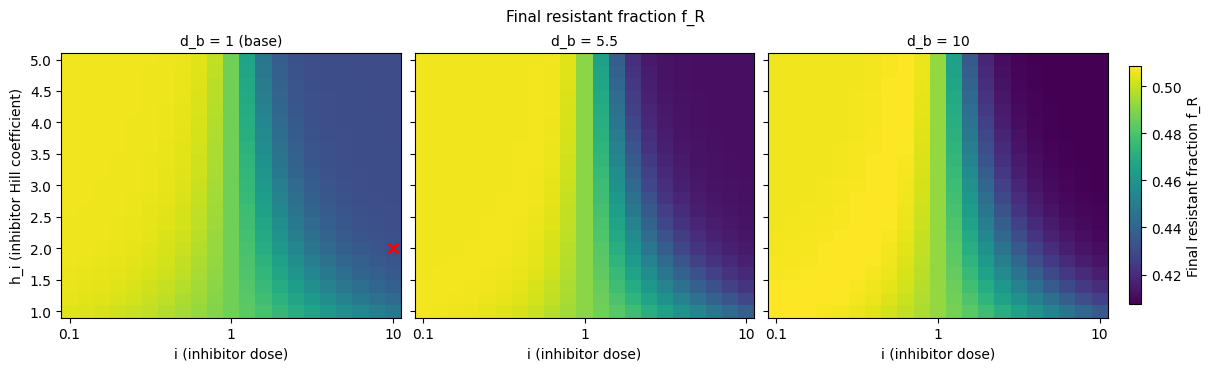

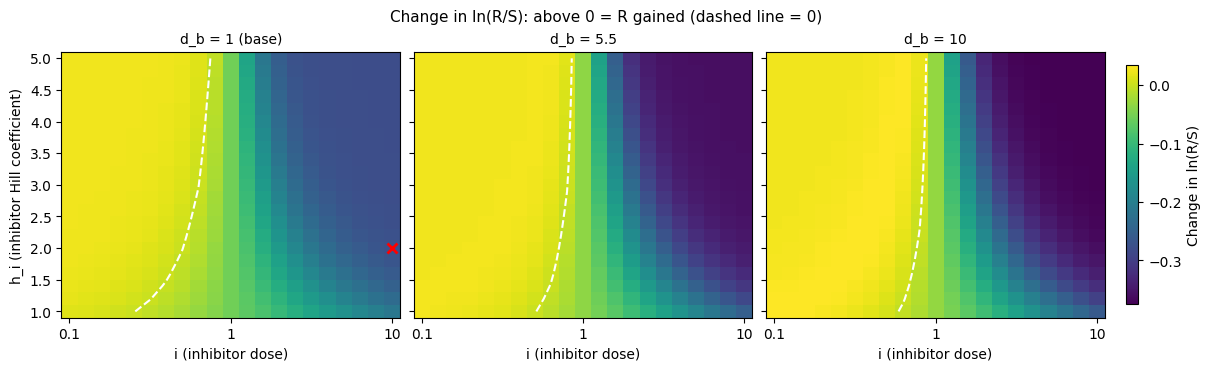

R gained in 43.7% of runs; f_R ranges from 0.407 to 0.509


In [4]:
SL = [1.0, 5.5, 10.0]
heatmap_slices(df, "i", "h_i", "f_R_final", "d_b", SL); plt.show()
heatmap_slices(df, "i", "h_i", "delta_log_ratio", "d_b", SL, diverging=True,
               title="Change in ln(R/S): above 0 = R gained (dashed line = 0)"); plt.show()
print(f"R gained in {(df.delta_log_ratio > 0).mean():.1%} of runs; f_R ranges from {df.f_R_final.min():.3f} to {df.f_R_final.max():.3f}")

## The three inhibitor parameters have two degrees of freedom

In the equations i and h_i appear only through ι = i^h_i/(1 + i^h_i), and d_b only through d_b·ι
(verified in notebook 00). So every endpoint must fall on a single curve when plotted against ι, for
a given d_b. The plot confirms it: points with different (i, h_i) but the same ι coincide.

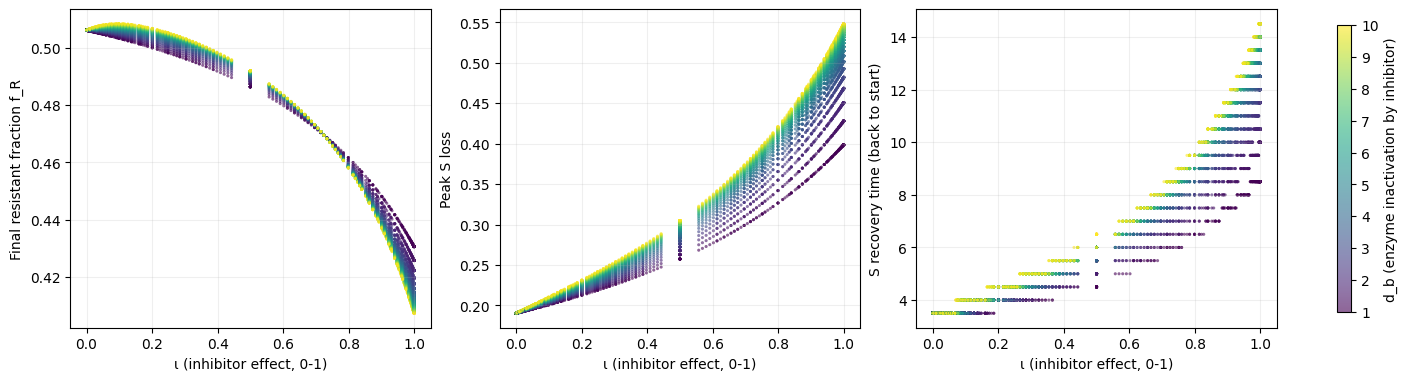

At d_b = 1: largest spread in f_R among runs sharing the same ι (to 3 decimals): 0.0002
ι ranges from 0.0000 to 1.0000; at the base point ι = 0.9901


In [5]:
df["iota"] = df.i ** df.h_i / (1 + df.i ** df.h_i)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), constrained_layout=True)
for ax, col in zip(axes, ["f_R_final", "peak_loss_S", "t_regain_S"]):
    sc = ax.scatter(df.iota, df[col], c=df.d_b, cmap="viridis", s=5, alpha=0.6, lw=0)
    ax.set(xlabel="ι (inhibitor effect, 0-1)", ylabel=label(col)); ax.grid(alpha=0.2)
fig.colorbar(sc, ax=axes, shrink=0.9).set_label(label("d_b"))
plt.show()
sub = select(df, {"d_b": 1.0}).sort_values("iota")
spread = sub.groupby(sub.iota.round(3)).f_R_final.agg(lambda s: s.max() - s.min()).max()
print(f"At d_b = 1: largest spread in f_R among runs sharing the same ι (to 3 decimals): {spread:.4f}")
print(f"ι ranges from {df.iota.min():.4f} to {df.iota.max():.4f}; at the base point ι = {10**2 / (1 + 10**2):.4f}")

## Depth of the crash and recovery time

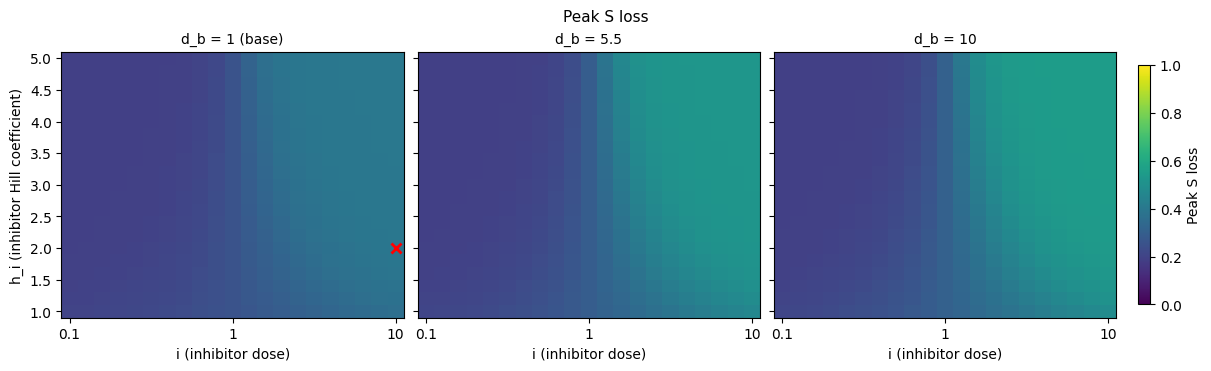

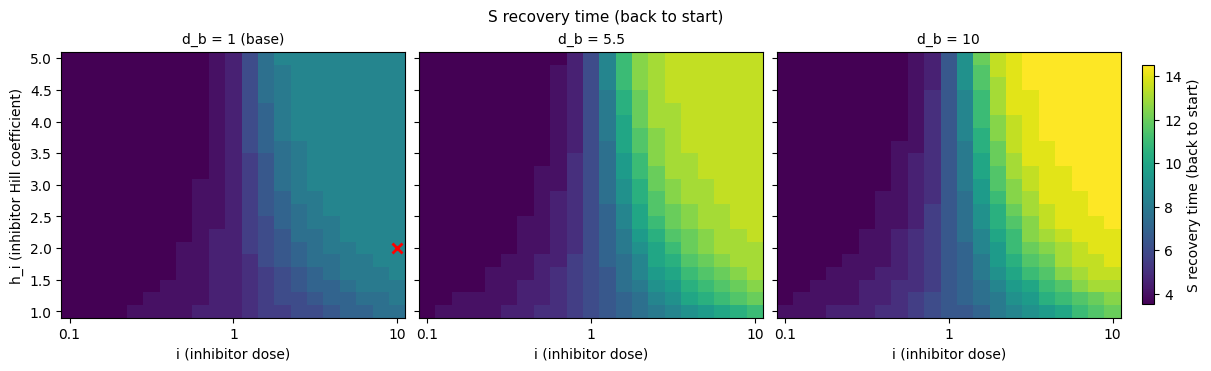

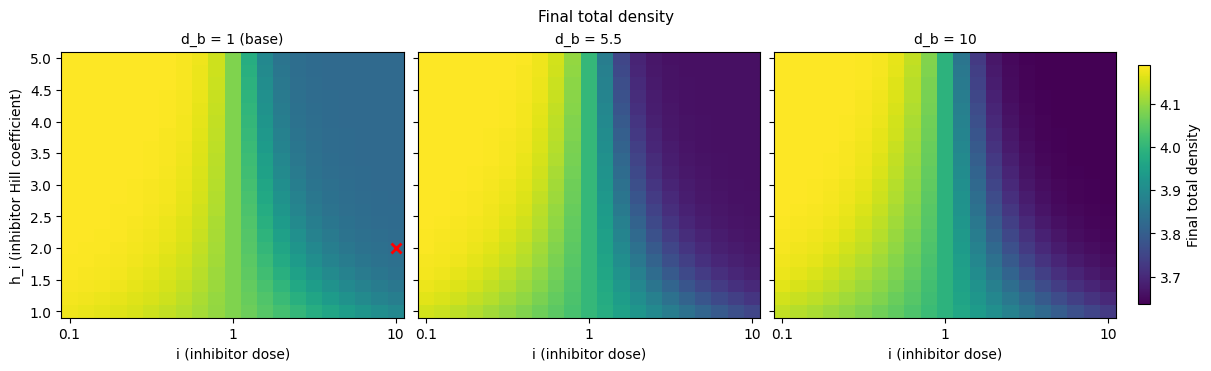

In [6]:
heatmap_slices(df, "i", "h_i", "peak_loss_S", "d_b", SL, vmin=0, vmax=1); plt.show()
heatmap_slices(df, "i", "h_i", "t_regain_S", "d_b", SL); plt.show()
heatmap_slices(df, "i", "h_i", "total_final", "d_b", SL); plt.show()

## Which of the inhibitor's three actions matters?

The inhibitor does three things: it reduces R's private protection (raises β), it reduces
antibiotic degradation by living R (lowers φ), and it inactivates free enzyme (d_b·ι). Below, the inhibitor
is allowed to act on only one of them at a time (the others see no inhibitor), at base parameters.

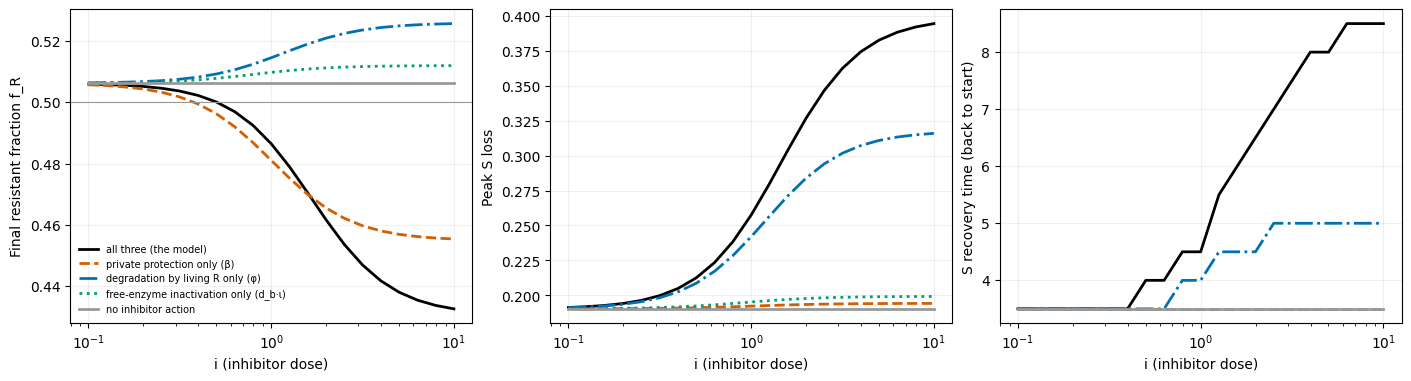

,f_R_final,peak_loss_S,t_regain_S,total_final
mode,,,,
full,0.433,0.394,8.5,3.832
private_only,0.455,0.194,3.5,4.179
degradation_only,0.526,0.316,5.0,4.097
turnover_only,0.512,0.199,3.5,4.149
none,0.506,0.190,3.5,4.188


In [7]:
modes = {"full": "all three (the model)", "private_only": "private protection only (β)",
         "degradation_only": "degradation by living R only (φ)", "turnover_only": "free-enzyme inactivation only (d_b·ι)",
         "none": "no inhibitor action"}
colors = [OKABE_ITO["black"], OKABE_ITO["vermillion"], OKABE_ITO["blue"], OKABE_ITO["green"], OKABE_ITO["grey"]]
i_axis = axis("i")
abl = pd.DataFrame([{"mode": m, "i": i, **engine.compute_endpoints(i_dose=float(i), ablation=m)}
                    for m in modes for i in i_axis])
abl.to_csv(TABLES / "inhibitor_pathway_ablation.csv", index=False, float_format="%.8g")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7), constrained_layout=True)
for ax, col in zip(axes, ["f_R_final", "peak_loss_S", "t_regain_S"]):
    for (m, name), colr, ls in zip(modes.items(), colors, ["-", "--", "-.", ":", "-"]):
        s = abl[abl["mode"] == m]
        ax.semilogx(s.i, s[col], color=colr, ls=ls, lw=2, label=name)
    ax.set(xlabel=label("i"), ylabel=label(col)); ax.grid(alpha=0.2)
axes[0].axhline(0.5, color="0.6", lw=0.8); axes[0].legend(frameon=False, fontsize=7)
plt.show()
abl[abl.i == 10.0].set_index("mode")[["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]].round(3)

## Outcome map

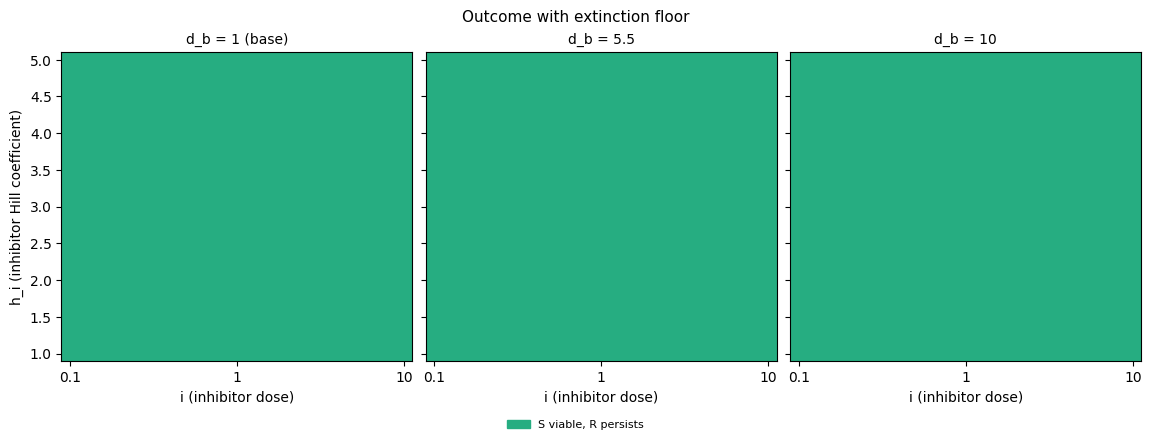

In [8]:
outcome_map(df, "i", "h_i", "d_b", SL); plt.show()

## Effect of each parameter

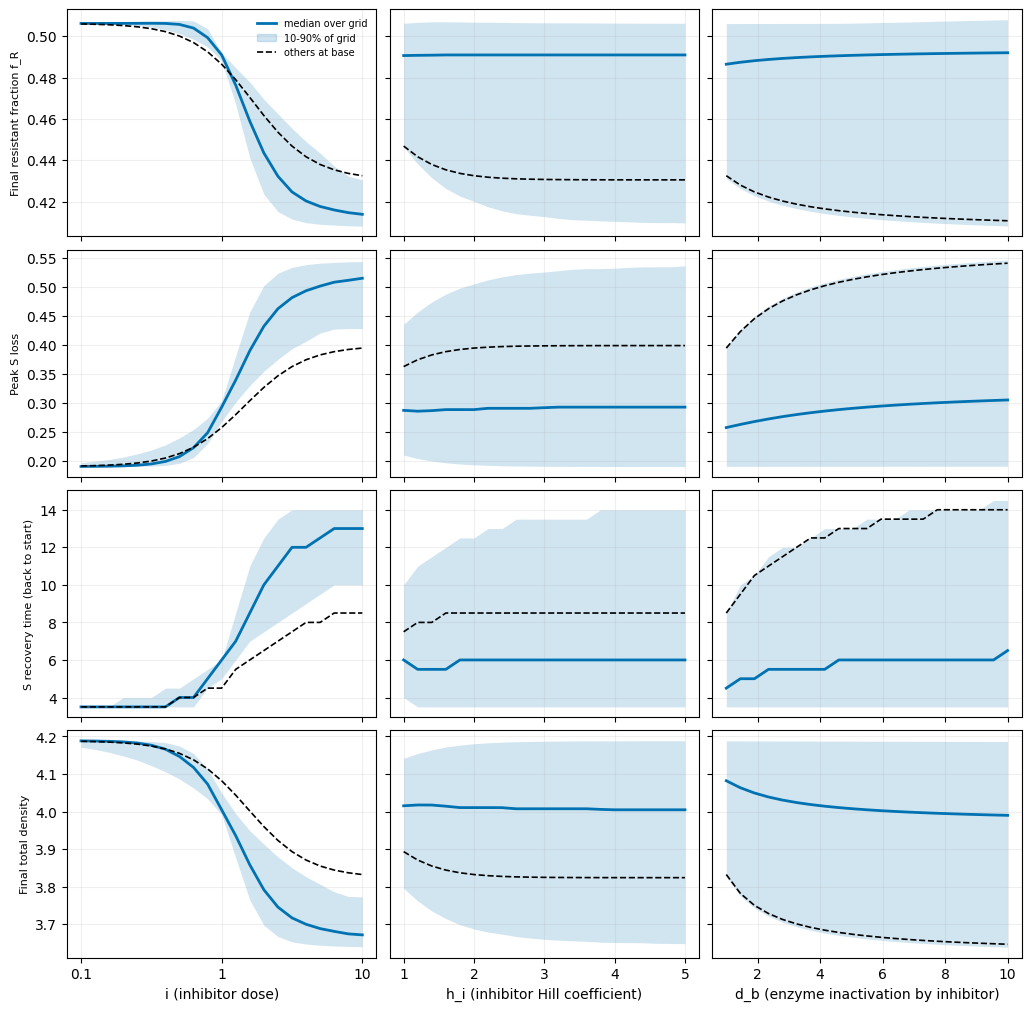

In [9]:
marginal_effects(df, PARAMS, ["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]); plt.show()

## Example time courses (base parameters, rising inhibitor dose)

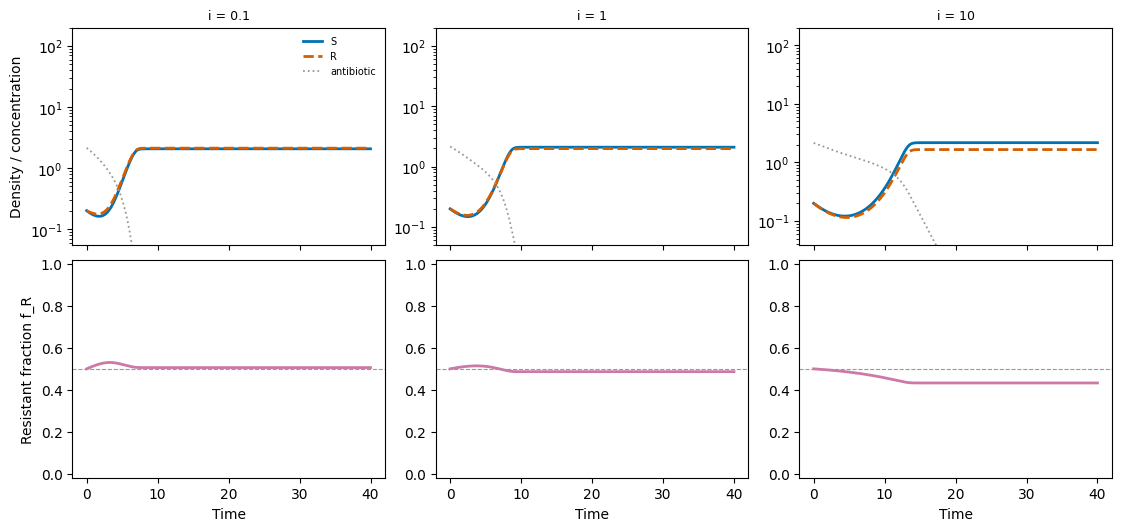

In [10]:
timecourses([(f"i = {i:g}", {"i": i}) for i in (0.1, 1.0, 10.0)], t_end=40); plt.show()

## Rank sensitivity over the whole grid

In [11]:
ends = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "t_regain_S", "t_steady_state"]
rho = pd.DataFrame({label(e): [settled[[p, e]].corr(method="spearman").iloc[0, 1] for p in PARAMS] for e in ends},
                   index=[SHORT[p] for p in PARAMS])
print("Spearman rank correlation between each parameter and each endpoint, over the whole grid:")
rho.round(2)

Spearman rank correlation between each parameter and each endpoint, over the whole grid:


,Final resistant fraction f_R,Final Shannon diversity H,Final total density,Peak S loss,S recovery time (back to start),Time to steady state
i,-0.91,-0.82,-0.94,0.94,0.93,0.94
h_i,-0.07,-0.14,0.03,-0.03,0.02,-0.02
d_b,0.08,-0.18,-0.14,0.14,0.15,0.14


## Takeaways

- **The inhibitor dose decides the direction of selection.** At base parameters R gains slightly when
  i is below about 0.5 and S gains above it. Over the grid R gains in 43.7% of runs: in every run with
  i ≤ 0.25, in 439 of 441 at i = 0.32, and in none with i ≥ 1.
- **At this antibiotic dose the effect on composition is modest:** final f_R only ranges from 0.41 to
  0.51. i has by far the largest rank correlation (−0.91); d_b is weak (+0.08). h_i has no one-directional
  effect: it raises ι for i > 1 and lowers it for i < 1, so its grid-wide rank correlation cancels
  (−0.07), but at a fixed dose it moves f_R by up to 0.06.
- **i and h_i act only through ι.** Runs with different (i, h_i) but the same ι = i^h_i/(1 + i^h_i) give
  the same result (largest spread in f_R: 0.0002). h_i only changes how quickly ι saturates with dose.
- **More inhibitor means a deeper crash for both strains.** At base, peak S loss rises from 19% (i = 0.1)
  to 39% (i = 10), recovery time from 3.5 to 8.5, and the final total falls from 4.19 to 3.83.
- **d_b deepens the crash further.** Faster inactivation of free enzyme leaves the antibiotic in place
  longer: at i = 10, peak S loss rises from 39% (d_b = 1) to 54% (d_b = 10), with a small extra drop in
  f_R (0.433 to 0.411).
- **Removing R's private protection is what selects against R.** Letting the inhibitor act on one
  mechanism at a time (i = 10): private protection only gives f_R = 0.455; blocking degradation by
  living R only gives 0.526 (R gains, and it causes most of the deeper crash); inactivating free
  enzyme only gives 0.512; no inhibitor gives 0.506. All three together give 0.433, more than the sum
  of the parts.
- **No run loses S or eradicates anything** at a0 = 2.15, with or without the extinction floor.